In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

df_reg = pd.read_csv('regression_rideBookings.csv', low_memory=False)

print("Shape of Data:", df_reg.shape)
print("\n--- Info ---")
df_reg.info()
display(df_reg.head())

Shape of Data: (150100, 21)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 150100 entries, 0 to 150099
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype
---  ------                             --------------   -----
 0   Date                               150086 non-null  str  
 1   Time                               150086 non-null  str  
 2   Booking ID                         150084 non-null  str  
 3   Booking Status                     150100 non-null  str  
 4   Customer ID                        150081 non-null  str  
 5   Vehicle Type                       150100 non-null  str  
 6   Pickup Location                    150082 non-null  str  
 7   Drop Location                      150085 non-null  str  
 8   Avg VTAT                           139587 non-null  str  
 9   Avg CTAT                           102087 non-null  str  
 10  Cancelled Rides by Customer        10600 non-null   str  
 11  Reason for cancelling by Customer 

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


In [21]:
df_dirty = df_reg.copy()

symbols = ['*', '?', '&', '%', '$', '#', '@']
np.random.seed(42)

for col in ['Ride Distance', 'Customer Rating']:
    mask = np.random.rand(len(df_dirty)) < 0.05
    random_symbols = np.random.choice(symbols, size=mask.sum())
    df_dirty.loc[mask, col] = random_symbols

print("Cleaning data and filtering wild outliers...")

cols_to_drop = [
    'Date', 'Time', 'Booking ID', 'Customer ID', 'Pickup Location', 
    'Drop Location', 'Reason for cancelling by Customer', 
    'Driver Cancellation Reason', 'Incomplete Rides Reason'
]
df_clean = df_dirty.drop(columns=cols_to_drop, errors='ignore').copy()

df_clean = df_clean.replace(symbols, np.nan)

numeric_candidates = [
    'Ride Distance', 'Customer Rating', 'Driver Ratings', 
    'Booking Value', 'Avg VTAT', 'Avg CTAT', 
    'Cancelled Rides by Customer', 'Cancelled Rides by Driver', 'Incomplete Rides'
]

for col in numeric_candidates:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

for col in ['Cancelled Rides by Customer', 'Cancelled Rides by Driver', 'Incomplete Rides']:
    df_clean[col] = df_clean[col].fillna(0)

df_clean = df_clean[(df_clean['Booking Value'] > 0) & (df_clean['Booking Value'] <= 5000)]
df_clean = df_clean[(df_clean['Ride Distance'] > 0) & (df_clean['Ride Distance'] <= 150)]

for col in ['Ride Distance', 'Customer Rating', 'Driver Ratings', 'Avg VTAT', 'Avg CTAT']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include=['object']).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print(f"Total remaining nulls: {df_clean.isnull().sum().sum()}")
print(f"Cleaned dataset rows: {len(df_clean)}")

Cleaning data and filtering wild outliers...
Total remaining nulls: 0
Cleaned dataset rows: 97008


In [15]:
df_clean['Is_Completed'] = df_clean['Booking Status'].apply(lambda x: 1 if x == 'Completed' else 0)
df_model = df_clean.drop(columns=['Booking Status'])

display(df_model.head())

,Vehicle Type,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Cancelled Rides by Driver,Incomplete Rides,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method,Is_Completed
0,eBike,8.3,28.8,1.0,1.0,1.0,414.0,23.72,4.3,4.5,UPI,0
1,Go Sedan,4.9,14.0,1.0,1.0,1.0,237.0,5.73,4.3,4.5,UPI,0
2,Auto,13.4,25.8,1.0,1.0,1.0,627.0,13.58,4.9,4.9,Debit Card,1
3,Premier Sedan,13.1,28.5,1.0,1.0,1.0,416.0,34.02,4.6,5.0,UPI,1
4,Bike,5.3,19.6,1.0,1.0,1.0,737.0,48.21,4.1,4.3,UPI,1


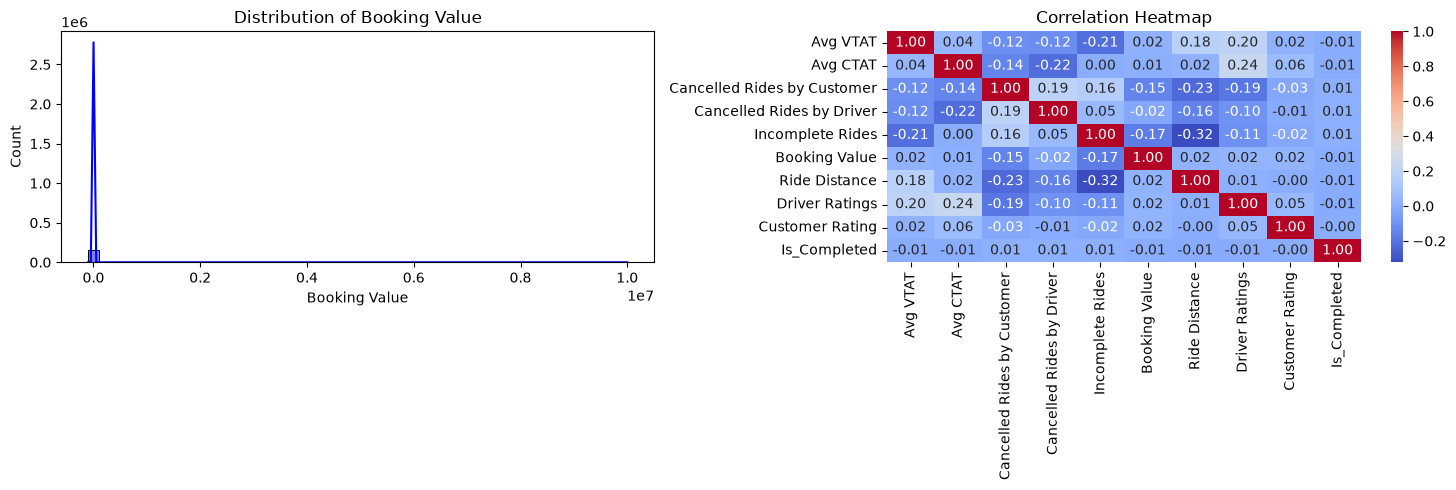

In [22]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_model['Booking Value'], bins=50, kde=True, color='blue')
plt.title('Distribution of Booking Value')

plt.subplot(1, 2, 2)
numeric_df = df_model.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

X = df_model.drop(columns=['Booking Value'])
y = df_model['Booking Value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape after preprocessing:", X_train_processed.shape)

Training shape after preprocessing: (120080, 21)


In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Training Linear Regression...")
lr_model = LinearRegression()
lr_model.fit(X_train_processed, y_train)

print("Training Random Forest Regressor...")
rf_model = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_processed, y_train)

lr_preds = lr_model.predict(X_test_processed)
rf_preds = rf_model.predict(X_test_processed)

def print_metrics(name, y_true, y_pred):
    print(f"--- {name} ---")
    print(f"R2 Score: {r2_score(y_true, y_pred):.4f}")
    print(f"RMSE:     {np.sqrt(mean_squared_error(y_true, y_pred)):.2f}")
    print(f"MAE:      {mean_absolute_error(y_true, y_pred):.2f}\n")

print_metrics("Linear Regression", y_test, lr_preds)
print_metrics("Random Forest", y_test, rf_preds)

Training Linear Regression...
Training Random Forest Regressor...
--- Linear Regression ---
R2 Score: -0.0195
RMSE:     58856.02
MAE:      1013.20

--- Random Forest ---
R2 Score: -0.0198
RMSE:     58864.85
MAE:      871.54



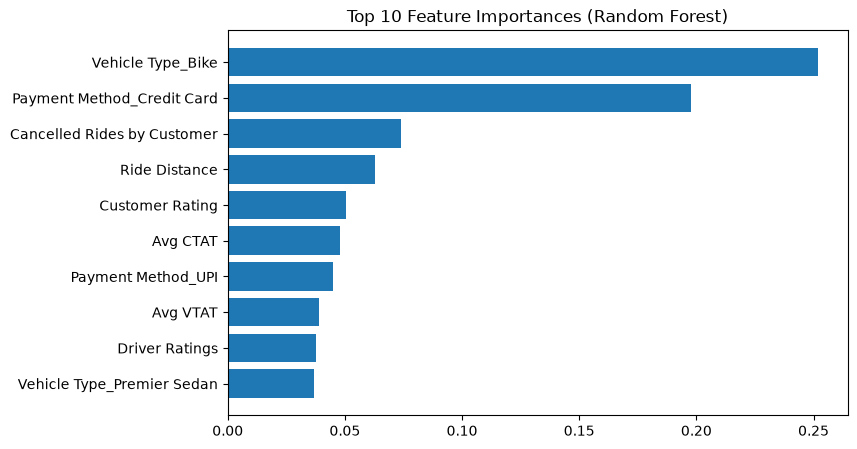

5-Fold CV R2 Scores: [ 0.01652194 -2.56807422 -0.01872084 -1.3472347  -2.02854145]
Mean CV R2: -1.1892


In [25]:
from sklearn.model_selection import cross_val_score

cat_encoded_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols))
feature_names = numeric_cols + cat_encoded_names
importances = rf_model.feature_importances_

indices = np.argsort(importances)[-10:]
plt.figure(figsize=(8, 5))
plt.barh(range(len(indices)), importances[indices], align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.title("Top 10 Feature Importances (Random Forest)")
plt.show()

cv_scores = cross_val_score(lr_model, X_train_processed, y_train, cv=5, scoring='r2')
print(f"5-Fold CV R2 Scores: {cv_scores}")
print(f"Mean CV R2: {cv_scores.mean():.4f}")

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')

print("1. Loading raw dataset...")
df_raw = pd.read_csv('regression_rideBookings.csv', low_memory=False)

print("2. Injecting dirty symbols (*, ?, &, %, $, #, @)...")
df_dirty = df_raw.copy()
symbols = ['*', '?', '&', '%', '$', '#', '@']
np.random.seed(42)

for col in ['Ride Distance', 'Customer Rating']:
    mask = np.random.rand(len(df_dirty)) < 0.05
    df_dirty.loc[mask, col] = np.random.choice(symbols, size=mask.sum())

print("3. Cleaning data and stripping wild 1-crore outliers...")
cols_to_drop = [
    'Date', 'Time', 'Booking ID', 'Customer ID', 'Pickup Location', 
    'Drop Location', 'Reason for cancelling by Customer', 
    'Driver Cancellation Reason', 'Incomplete Rides Reason'
]
df_clean = df_dirty.drop(columns=cols_to_drop, errors='ignore').copy()

df_clean = df_clean.replace(symbols, np.nan)

numeric_cols = [
    'Ride Distance', 'Customer Rating', 'Driver Ratings', 
    'Booking Value', 'Avg VTAT', 'Avg CTAT', 
    'Cancelled Rides by Customer', 'Cancelled Rides by Driver', 'Incomplete Rides'
]
for col in numeric_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

for col in ['Cancelled Rides by Customer', 'Cancelled Rides by Driver', 'Incomplete Rides']:
    df_clean[col] = df_clean[col].fillna(0)

df_clean = df_clean[(df_clean['Booking Value'] > 0) & (df_clean['Booking Value'] <= 5000)]
df_clean = df_clean[(df_clean['Ride Distance'] > 0) & (df_clean['Ride Distance'] <= 150)]

for col in ['Ride Distance', 'Customer Rating', 'Driver Ratings', 'Avg VTAT', 'Avg CTAT']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include=['object']).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

df_clean['Is_Completed'] = (df_clean['Booking Status'] == 'Completed').astype(int)
df_clean.drop(columns=['Booking Status'], inplace=True)

print("4. Splitting and Preprocessing...")
X = df_clean.drop(columns=['Booking Value'])
y = df_clean['Booking Value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

cat_features = X.select_dtypes(include=['object']).columns.tolist()
num_features = X.select_dtypes(include=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ]
)

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print("5. Training Random Forest Regressor on clean data...")
rf_model = RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_p, y_train)

rf_preds = rf_model.predict(X_test_p)
print("\n--- MODEL PERFORMANCE ---")
print(f"R2 Score: {r2_score(y_test, rf_preds):.4f}")
print(f"MAE:      ₹{mean_absolute_error(y_test, rf_preds):.2f}")
print(f"RMSE:     ₹{np.sqrt(mean_squared_error(y_test, rf_preds)):.2f}")

joblib.dump(rf_model, 'rf_ride_model.pkl')
joblib.dump(preprocessor, 'ride_preprocessor.pkl')
print("\nArtifacts successfully overwritten.")

demo_data = pd.DataFrame([{
    'Vehicle Type': 'Premier Sedan',
    'Avg VTAT': 5.0,
    'Avg CTAT': 3.0,
    'Cancelled Rides by Customer': 0,
    'Cancelled Rides by Driver': 0,
    'Incomplete Rides': 0,
    'Ride Distance': 15.5,
    'Driver Ratings': 4.8,
    'Customer Rating': 4.5,
    'Payment Method': 'UPI',
    'Is_Completed': 1
}])

loaded_prep = joblib.load('ride_preprocessor.pkl')
loaded_model = joblib.load('rf_ride_model.pkl')

demo_p = loaded_prep.transform(demo_data)
final_price = loaded_model.predict(demo_p)[0]

print("\n--- LIVE DEMO PREDICTION ---")
print(f"Predicted Booking Value for 15.5km Premier Sedan ride: ₹{final_price:.2f}")

1. Loading raw dataset...
2. Injecting dirty symbols (*, ?, &, %, $, #, @)...
3. Cleaning data and stripping wild 1-crore outliers...
4. Splitting and Preprocessing...
5. Training Random Forest Regressor on clean data...

--- MODEL PERFORMANCE ---
R2 Score: -0.0045
MAE:      ₹283.38
RMSE:     ₹388.72

Artifacts successfully overwritten.

--- LIVE DEMO PREDICTION ---
Predicted Booking Value for 15.5km Premier Sedan ride: ₹508.63
